In [1]:
pip install pyspark


Note: you may need to restart the kernel to use updated packages.


In [12]:
import pyspark
from pyspark.sql.types import *
from pyspark.sql.functions import concat, col, substring, lit
import pandas as pd
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("PySparkExample").getOrCreate()
#LINK TO CSV file : https://data.gov.lv/dati/lv/dataset/uz/resource/25e80bf3-f107-4ab4-89ef-251b5b9374e9?inner_span=True
df = spark.read.option("inferSchema",True) \
                .option("header",True) \
                .option("delimiter",";") \
  .csv("register.csv")
df.show()
table_name="my_table"
df.createOrReplaceTempView(table_name)
df.printSchema()

+-----------+------------------+--------------------+--------------------+--------------------+-----------------+--------------+-------+--------------------+----+--------------------+----------+----------+------+--------------------+-----+---------+---------+---------+------+-------------------+
|    regcode|              sepa|                name|  name_before_quotes|      name_in_quotes|name_after_quotes|without_quotes|regtype|        regtype_text|type|           type_text|registered|terminated|closed|             address|index|addressid|   region|     city|  atvk|reregistration_term|
+-----------+------------------+--------------------+--------------------+--------------------+-----------------+--------------+-------+--------------------+----+--------------------+----------+----------+------+--------------------+-----+---------+---------+---------+------+-------------------+
|41202013815|LV53ZZZ41202013815|"IK ""KRASTNIEKI ...|                  IK|      KRASTNIEKI A I|             N

In [3]:
test=spark.sql("select SUBSTRING((registered), 1, 7) AS subreg,count(*) AS REG_SK_D_PA_MEN from (select registered from my_table  where registered between '2023-09-30' and  '2026-09-30' order by registered DESC) group by subreg order by subreg DESC;").show()

+-------+---------------+
| subreg|REG_SK_D_PA_MEN|
+-------+---------------+
|2026-09|           1213|
|2026-08|           1065|
|2026-07|            991|
|2026-06|            876|
|2026-05|            942|
|2026-04|           1028|
|2026-03|           1158|
|2026-02|           1053|
|2026-01|           1080|
|2025-12|            887|
|2025-11|            910|
|2025-10|           1136|
|2025-09|           1115|
|2025-08|            966|
|2025-07|           1038|
|2025-06|            828|
|2025-05|            934|
|2025-04|            925|
|2025-03|           1011|
|2025-02|            992|
+-------+---------------+
only showing top 20 rows


In [4]:
test=spark.sql("select SUBSTRING((registered), 1, 7) AS subreg,count(*) AS REG_SK_D_PA_MEN_1_tp from (select registered, type from my_table  where registered between '2023-09-30' and  '2026-09-30' AND type='AKF' order by registered DESC) group by subreg order by subreg DESC;").show()

+-------+--------------------+
| subreg|REG_SK_D_PA_MEN_1_tp|
+-------+--------------------+
|2026-09|                   4|
|2026-08|                   4|
|2026-07|                   4|
|2026-06|                   3|
|2026-05|                   5|
|2026-04|                   6|
|2026-03|                   4|
|2026-02|                   4|
|2026-01|                   7|
|2025-12|                   7|
|2025-11|                   2|
|2025-10|                   4|
|2025-09|                   4|
|2025-08|                   3|
|2025-07|                   3|
|2025-06|                   2|
|2025-05|                   4|
|2025-04|                   5|
|2025-03|                   3|
|2025-02|                   4|
+-------+--------------------+
only showing top 20 rows


In [5]:
test=spark.sql("select distinct type from my_table order by type asc").show()

+--------------------+
|                type|
+--------------------+
|                 AKF|
|                 ARA|
|                 ARB|
|                 ARV|
|                  AS|
|                 ASF|
|                 BAZ|
|                 BDR|
|Biedrību un nodib...|
|                 DIE|
|                 DRZ|
|                 EIG|
|                 FIL|
|                 GIM|
|                  IK|
|                 IND|
|                 KAT|
|                  KB|
|                 KBS|
|                 KBU|
+--------------------+
only showing top 20 rows


In [6]:
test=spark.sql("select SUBSTRING(registered, 1, 7) AS subreg, type, count(*) from my_table  where registered between '2023-09-30' and  '2026-09-30' group by subreg, type order by subreg DESC;").show()

+-------+----+--------+
| subreg|type|count(1)|
+-------+----+--------+
|2026-09| SIA|    1020|
|2026-09|  KS|       1|
|2026-09| AKF|       4|
|2026-09| BDR|      80|
|2026-09| MIL|      10|
|2026-09|  AS|       1|
|2026-09| POR|       1|
|2026-09| FIL|       2|
|2026-09|  PS|       2|
|2026-09|  IK|      83|
|2026-09| IND|       1|
|2026-09| ZEM|       2|
|2026-09|  KB|       2|
|2026-09| NOD|       3|
|2026-09| PAR|       1|
|2026-08|  AS|       1|
|2026-08| MIL|       1|
|2026-08| NOD|       4|
|2026-08| ARB|       1|
|2026-08| SIA|     909|
+-------+----+--------+
only showing top 20 rows


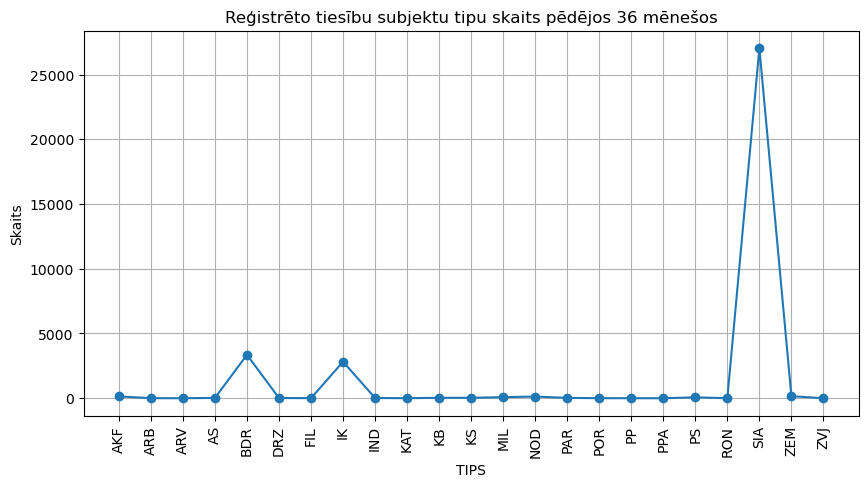

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Advanced data analysis with visualization
salary_trends = spark.sql('''
select type, count(*) AS sk from my_table  where registered between '2023-09-30' and  '2026-09-30' group by type order by type ASC;
''').toPandas()

# Visualization of ...
plt.figure(figsize=(10, 5))
plt.plot(salary_trends['type'], salary_trends['sk'], marker='o')
plt.xlabel('TIPS')
plt.ylabel('Skaits')
plt.title('Reģistrēto tiesību subjektu tipu skaits pēdējos 36 mēnešos')
plt.grid(True)
plt.xticks(rotation=90)
plt.show()

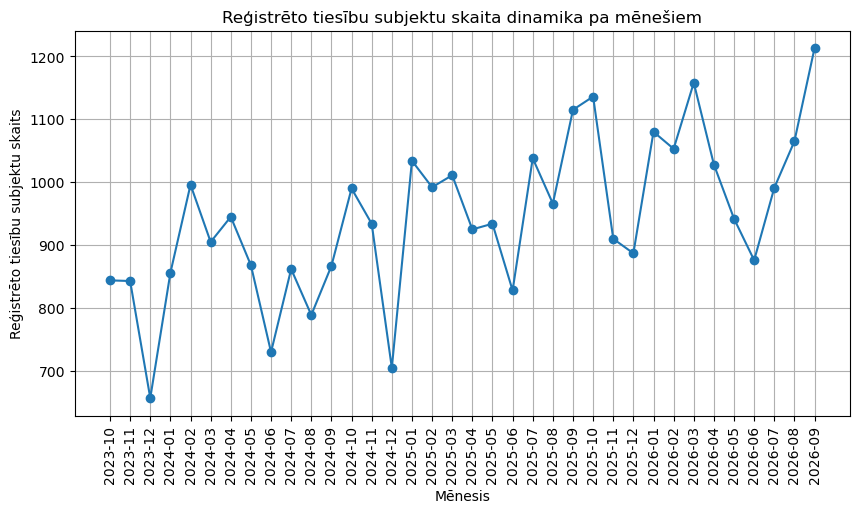

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Advanced data analysis with visualization
salary_trends = spark.sql('''
select SUBSTRING((registered), 1, 7) AS subreg,count(*) AS sk from (select registered from my_table  where registered between '2023-09-30' and  '2026-09-30' order by registered asc) group by subreg order by subreg ASC;
''').toPandas()

# Visualization of ...
plt.figure(figsize=(10, 5))
plt.plot(salary_trends['subreg'], salary_trends['sk'], marker='o')
plt.xlabel('Mēnesis')
plt.ylabel('Reģistrēto tiesību subjektu skaits')
plt.title('Reģistrēto tiesību subjektu skaita dinamika pa mēnešiem')
plt.grid(True)
plt.xticks(rotation=90)
plt.show()

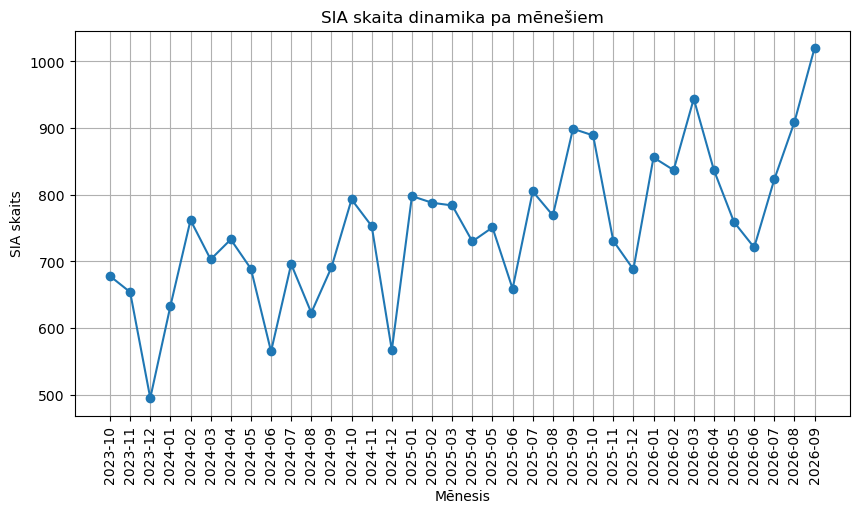

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# Advanced data analysis with visualization
salary_trends = spark.sql('''
select SUBSTRING(registered, 1, 7) AS subreg, count(*) as sk from my_table  where registered between '2023-09-30' and  '2026-09-30' AND type='SIA' group by subreg, type order by subreg ASC;
''').toPandas()

# Visualization of ...
plt.figure(figsize=(10, 5))
plt.plot(salary_trends['subreg'], salary_trends['sk'], marker='o')
plt.xlabel('Mēnesis')
plt.ylabel('SIA skaits')
plt.title('SIA skaita dinamika pa mēnešiem')
plt.grid(True)
plt.xticks(rotation=90)
plt.show()

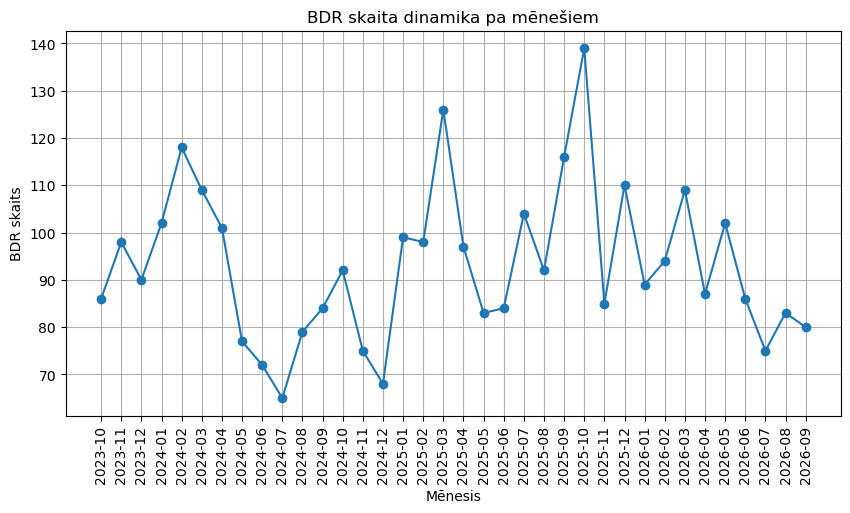

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Advanced data analysis with visualization
salary_trends = spark.sql('''
select SUBSTRING(registered, 1, 7) AS subreg, count(*) as sk from my_table  where registered between '2023-09-30' and  '2026-09-30' AND type='BDR' group by subreg, type order by subreg ASC;
''').toPandas()

# Visualization of ...
plt.figure(figsize=(10, 5))
plt.plot(salary_trends['subreg'], salary_trends['sk'], marker='o')
plt.xlabel('Mēnesis')
plt.ylabel('BDR skaits')
plt.title('BDR skaita dinamika pa mēnešiem')
plt.grid(True)
plt.xticks(rotation=90)
plt.show()

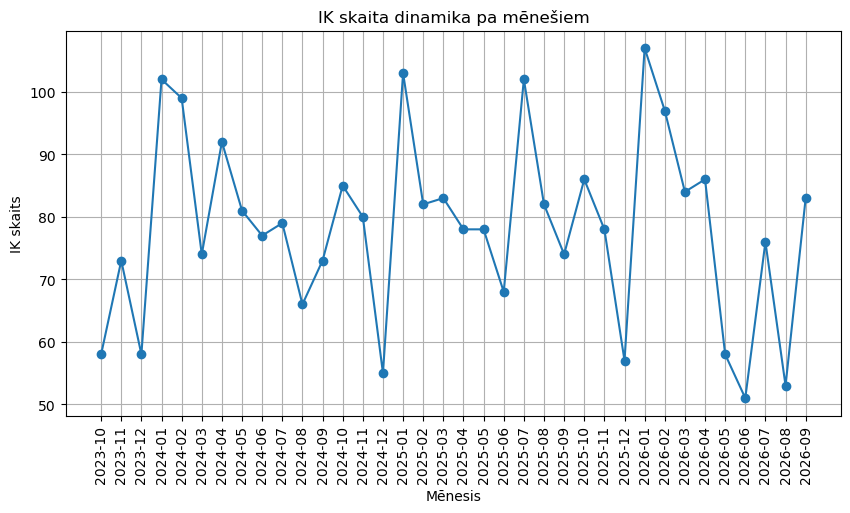

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Advanced data analysis with visualization
salary_trends = spark.sql('''
select SUBSTRING(registered, 1, 7) AS subreg, count(*) as sk from my_table  where registered between '2023-09-30' and  '2026-09-30' AND type='IK' group by subreg, type order by subreg ASC;
''').toPandas()

# Visualization of ...
plt.figure(figsize=(10, 5))
plt.plot(salary_trends['subreg'], salary_trends['sk'], marker='o')
plt.xlabel('Mēnesis')
plt.ylabel('IK skaits')
plt.title('IK skaita dinamika pa mēnešiem')
plt.grid(True)
plt.xticks(rotation=90)
plt.show()